# Figure S4 — Robustness to erroneous priors

Source: `robustness/do_vis_robustness.py` and the saved malignant-gene-set metrics.
Use the four gene-set metrics, not the separate Moran's I results.
The experiment spans 0-100% prior error in 5% steps, with five repeats per configuration/error rate. The gene-set definition is included.
Preserve the source behavior: keep the last record for each `(error_rate, repeat, seed, method, metric)` key.
Shading is mean +/- 1.96 * sample SD / sqrt(n); dashed lines use the original anno-NK baseline rows.
These are normal-approximation CIs, not t intervals. Panel order follows the figure: F1, capture, eta-squared and gap.

**Paths:** The first code cell discovers the data root and prints every input path. If needed, edit `DATA_ROOT` or individual entries in `DATA_FILES` there, then rerun from that cell. Bundled tables and outputs always use this supplementary folder. See `README.md` for details.


In [1]:
FIGURE = 'figS4'

from pathlib import Path

# Leave both settings as None to discover this folder and the data automatically.
# DATA_ROOT may be an absolute path or a path relative to this notebook folder.
SUPP_DIR = None  # Set only if the kernel starts outside the repository/workspace.
DATA_ROOT = None  # Explicit setting takes priority over LASSOARE_DATA_ROOT.

# Relative input paths use DATA_ROOT; individual absolute paths are also supported.
DATA_FILES = {
}

import os
import runpy

# An explicit folder or VS Code's notebook location takes priority over kernel cwd.
_folder = SUPP_DIR if SUPP_DIR is not None else os.environ.get('LASSOARE_SUPPLEMENTARY_DIR')
if _folder is not None:
    _candidates = [Path(_folder).expanduser().resolve()]
else:
    _anchors = []
    if globals().get('__vsc_ipynb_file__'):
        _anchors.append(Path(__vsc_ipynb_file__).expanduser().resolve().parent)
    _anchors.append(Path.cwd())
    _candidates = []
    for _anchor in _anchors:
        for _base in (_anchor, *_anchor.parents):
            _candidates.extend([
                _base, _base / 'supplementary', _base / 'figures_res/supplementary',
                _base / 'Lasso-ARE/figures_res/supplementary',
                _base / 'git_version/Lasso-ARE/figures_res/supplementary',
            ])
SUPP_DIR = next((_p.resolve() for _p in _candidates
                 if all((_p / _name).is_file() for _name in
                        ('supplementary_paths.py', 'supplementary_utils.py', 'inputs/manifest.json'))), None)
if SUPP_DIR is None:
    raise FileNotFoundError(
        f'Cannot locate the supplementary notebook folder from {Path.cwd()}. '
        'Set SUPP_DIR in this cell to the folder containing this notebook, '
        'supplementary_paths.py, supplementary_utils.py and inputs/.'
    )

# Load this copy directly, even if another supplementary folder was used by the kernel.
_paths = runpy.run_path(str(SUPP_DIR / 'supplementary_paths.py'))
_helpers = runpy.run_path(str(SUPP_DIR / 'supplementary_utils.py'))
for _name in ('require_file', 'read_metadata', 'read_expression', 'selection_mask',
              'set_selection', 'save_figure', 'plot_embedding'):
    globals()[_name] = _helpers[_name]
REPO_ROOT = _paths['repository_root'](SUPP_DIR)
DATA_ROOT, DATA_PATHS = _paths['resolve_data_paths'](SUPP_DIR, DATA_FILES, DATA_ROOT)
INPUT_DIR = SUPP_DIR / 'inputs'
OUTPUT_DIR = SUPP_DIR / 'output' / FIGURE
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'pdf.fonttype': 42, 'ps.fonttype': 42, 'font.family': 'DejaVu Sans'})
_paths['report_paths'](SUPP_DIR, DATA_ROOT, DATA_PATHS, OUTPUT_DIR)


Notebook folder: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary
Bundled inputs: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary/inputs
H5AD inputs: none (bundled result tables only)
Outputs: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary/output/figS4


In [2]:
METRICS = ['malignant_high_score_f1', 'malignant_high_score_capture',
           'malignant_score_eta_squared', 'top_cluster_score_gap']
METHOD_COLORS = {'lasso': '#6EC6B8', 'woLasso': '#9DB7E5', 'original': '#C9B8E8'}
METHOD_LABELS = {'lasso': 'PARE', 'woLasso': 'w/o Lasso', 'original': 'Original anno-NK'}
METRIC_LABELS = {'malignant_high_score_f1': 'High-score F1',
    'malignant_high_score_capture': 'High-score capture',
    'malignant_score_eta_squared': 'Malignant score eta squared', 'top_cluster_score_gap': 'Top cluster score gap'}

In [3]:
def _metric_label(metric):
    return METRIC_LABELS.get(metric, metric.replace("_", " ").title())

def _prepare_dataframe(input_csv):
    df = pd.read_csv(input_csv)
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    df["error_rate_numeric"] = pd.to_numeric(df["error_rate"], errors="coerce")
    experiment_key = ["error_rate", "repeat", "seed", "method", "metric"]
    if all(column in df.columns for column in experiment_key):
        duplicate_count = int(df.duplicated(experiment_key, keep="last").sum())
        if duplicate_count:
            print(f"Ignoring {duplicate_count} duplicate experiment records.")
            df = df.drop_duplicates(experiment_key, keep="last").copy()
    return df

def _summarize(df):
    experiment_df = df[df["error_rate_numeric"].notna()].copy()
    grouped = (
        experiment_df.groupby(["metric", "method", "error_rate_numeric"], as_index=False)
        .agg(mean=("value", "mean"), std=("value", "std"), count=("value", "count"))
    )
    grouped["std"] = grouped["std"].fillna(0.0)
    grouped["ci95"] = 1.96 * grouped["std"] / np.sqrt(grouped["count"].clip(lower=1))
    grouped.loc[grouped["count"] <= 1, "ci95"] = 0.0
    return grouped

def _baseline_values(df):
    baseline_df = df[(df["error_rate"].astype(str) == "baseline") & (df["method"] == "original")]
    if baseline_df.empty:
        return {}
    return baseline_df.groupby("metric")["value"].mean().to_dict()

def _style_axes(ax):
    ax.set_facecolor("#FBFCFE")
    ax.grid(True, axis="y", color="#E8EDF5", linewidth=0.9)
    ax.grid(True, axis="x", color="#F2F5FA", linewidth=0.6)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    for spine in ("left", "bottom"):
        ax.spines[spine].set_color("#D7DEE9")
    ax.tick_params(colors="#526070", labelsize=9)
    ax.xaxis.label.set_color("#394657")
    ax.yaxis.label.set_color("#394657")
    ax.title.set_color("#263445")

def _plot_metric(ax, summary, metric, baseline_values):
    metric_df = summary[summary["metric"] == metric]
    for method in ["woLasso", "lasso"]:
        method_df = metric_df[metric_df["method"] == method].sort_values("error_rate_numeric")
        if method_df.empty:
            continue
        x = method_df["error_rate_numeric"].to_numpy(dtype=float)
        y = method_df["mean"].to_numpy(dtype=float)
        ci = method_df["ci95"].to_numpy(dtype=float)
        color = METHOD_COLORS.get(method, "#999999")
        ax.plot(
            x,
            y,
            color=color,
            marker="o",
            markersize=4.5,
            linewidth=2.2,
            label=METHOD_LABELS.get(method, method),
        )
        ax.fill_between(x, y - ci, y + ci, color=color, alpha=0.18, linewidth=0)

    if metric in baseline_values and np.isfinite(baseline_values[metric]):
        ax.axhline(
            baseline_values[metric],
            color="#B8A6D9",
            linestyle=(0, (4, 3)),
            linewidth=1.7,
            label=METHOD_LABELS["original"],
        )

    ax.set_title(_metric_label(metric), fontsize=11, pad=8)
    ax.set_xlabel("Error rate")
    ax.set_ylabel("Value")
    _style_axes(ax)

Ignoring 2198 duplicate experiment records.


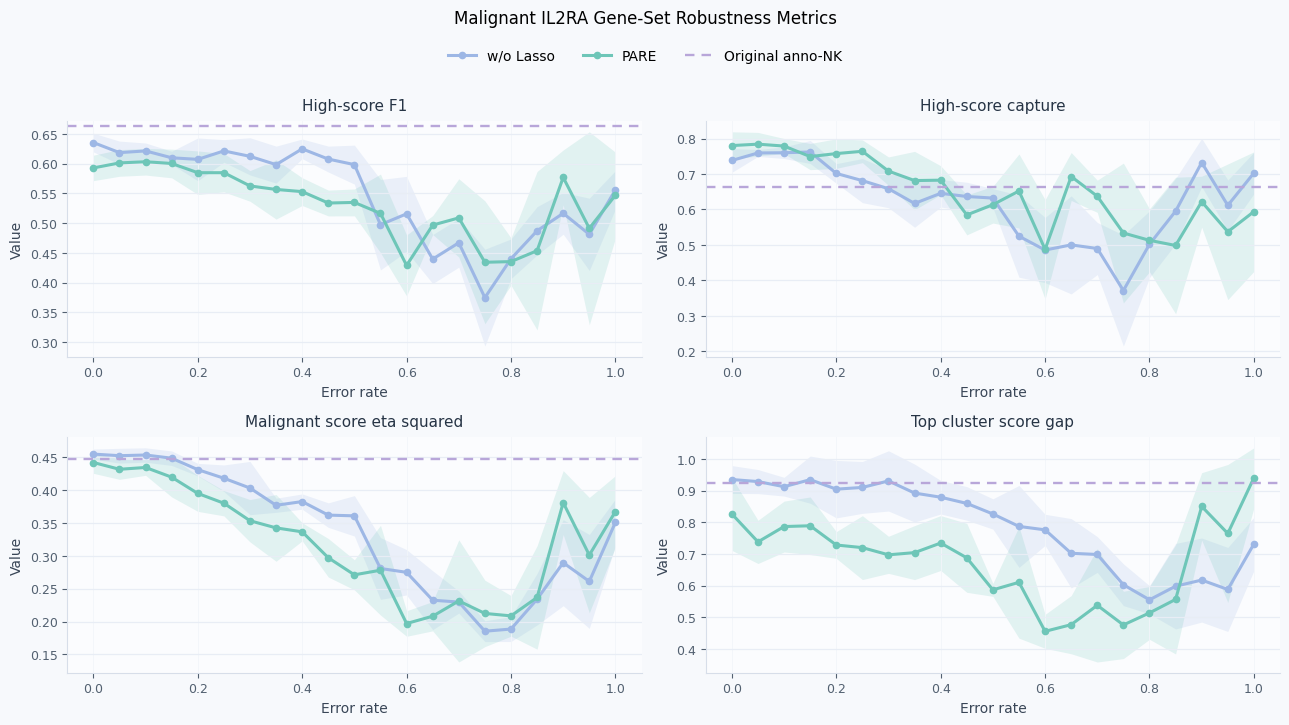

In [4]:
df = _prepare_dataframe(require_file(INPUT_DIR / 'figS4/robustness_malignant_gene_set_metrics.csv'))
summary = _summarize(df)
baseline = _baseline_values(df)
for metric in METRICS:
    if metric not in baseline or not np.isfinite(baseline[metric]):
        raise ValueError(f'Missing manual annotation baseline: {metric}')
    for method in ['lasso', 'woLasso']:
        values = summary[(summary['metric'] == metric) & (summary['method'] == method)]
        if len(values) != 21 or not np.allclose(sorted(values['error_rate_numeric']), np.linspace(0, 1, 21)):
            raise ValueError(f'Incomplete error-rate grid for {method}/{metric}')
        if not (values['count'] == 5).all():
            raise ValueError(f'Expected 5 repeats for {method}/{metric}')
fig, axes = plt.subplots(2, 2, figsize=(13, 6.8))
fig.patch.set_facecolor('#F7F9FC')
for ax, metric in zip(axes.ravel(), METRICS):
    _plot_metric(ax, summary, metric, baseline)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.suptitle('Malignant IL2RA Gene-Set Robustness Metrics', y=1.06)
fig.tight_layout()
save_figure(fig, OUTPUT_DIR, 'figS4_robustness_overview')
summary[summary['metric'].isin(METRICS)].to_csv(OUTPUT_DIR / 'figS4_plot_summary.csv', index=False)
pd.Series({m: baseline[m] for m in METRICS}, name='manual_annotation').to_csv(OUTPUT_DIR / 'figS4_baselines.csv')

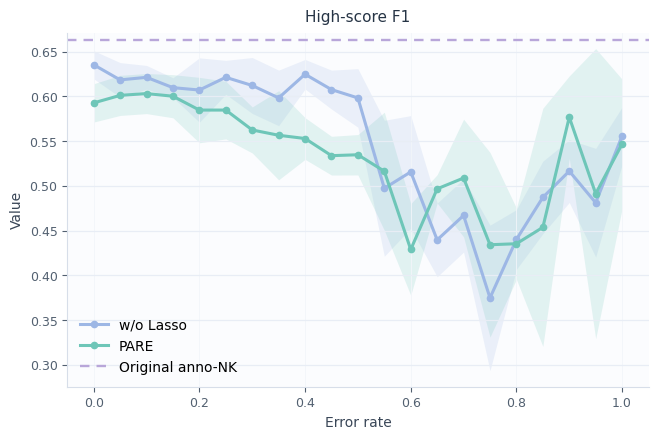

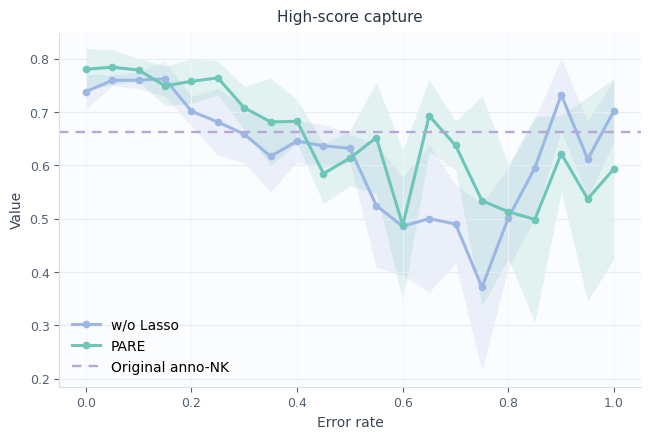

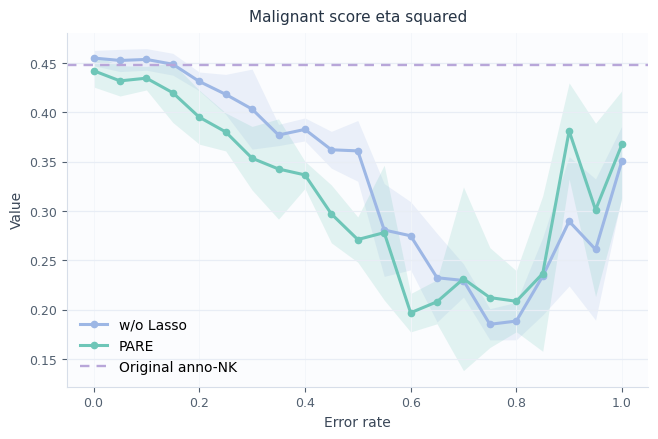

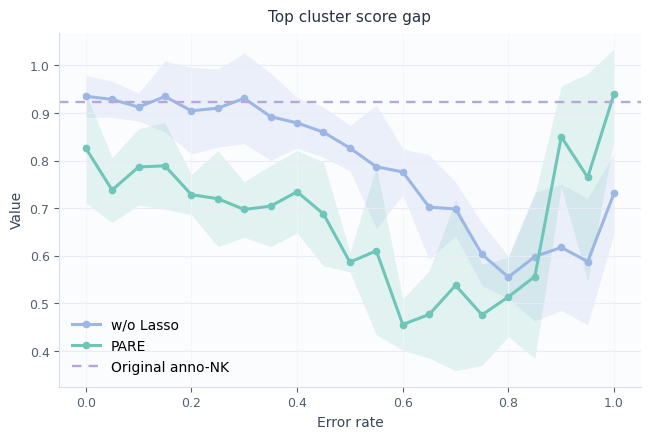

In [5]:
for metric in METRICS:
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    _plot_metric(ax, summary, metric, baseline)
    ax.legend(frameon=False)
    save_figure(fig, OUTPUT_DIR, f'figS4_{metric}')